CUSTOMER DATA
   CustomerID  Age  Gender     Location  TotalPurchases  TotalAmountSpent  \
0           1   68  Female      Houston              24            595.11   
1           2   35    Male      Phoenix              29           2901.57   
2           3   60    Male      Phoenix              19           4109.95   
3           4   63  Female      Chicago              27           2324.75   
4           5   42    Male  Los Angeles              15           1122.67   

  LastPurchaseDate  
0       2023-01-01  
1       2023-01-08  
2       2023-01-15  
3       2023-01-22  
4       2023-01-29  
Dataset Shape
(100, 7)
Column Names
Index(['CustomerID', 'Age', 'Gender', 'Location', 'TotalPurchases',
       'TotalAmountSpent', 'LastPurchaseDate'],
      dtype='object')
Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   C

/tmp/ipykernel_2366/1307294024.py:22: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["Age"].fillna(df["Age"].mean(), inplace=True)
/tmp/ipykernel_2366/1307294024.py:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', tr

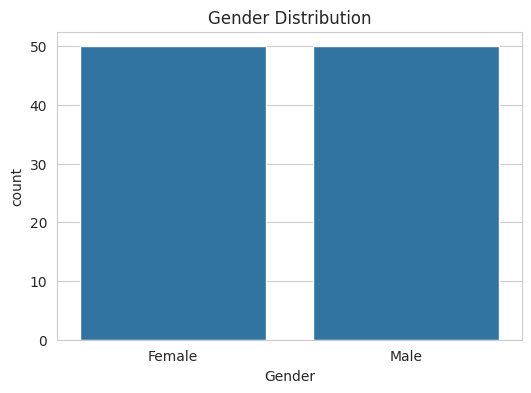

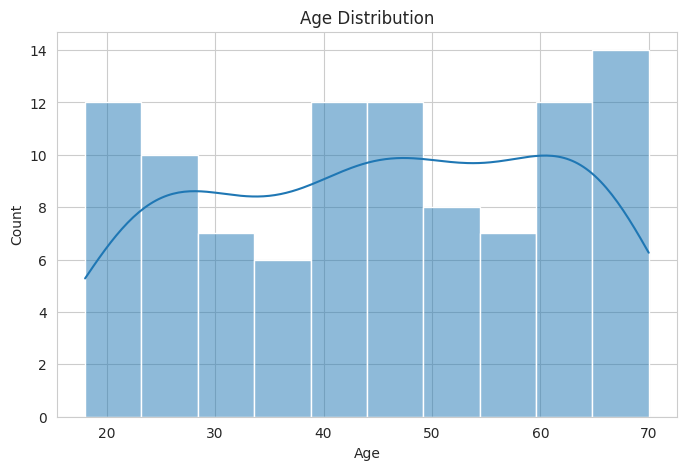

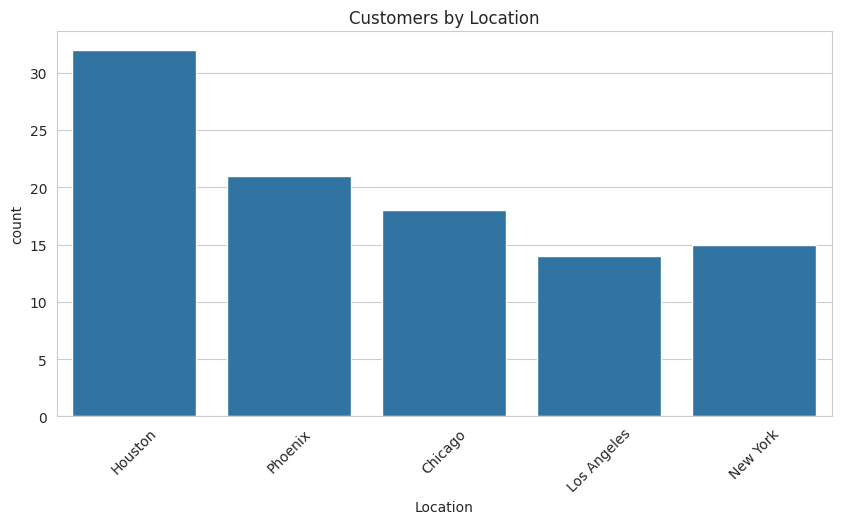

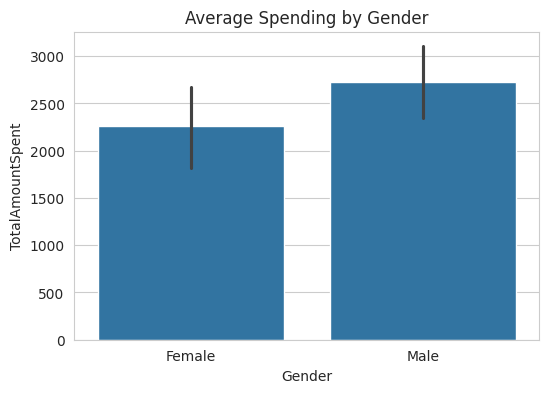

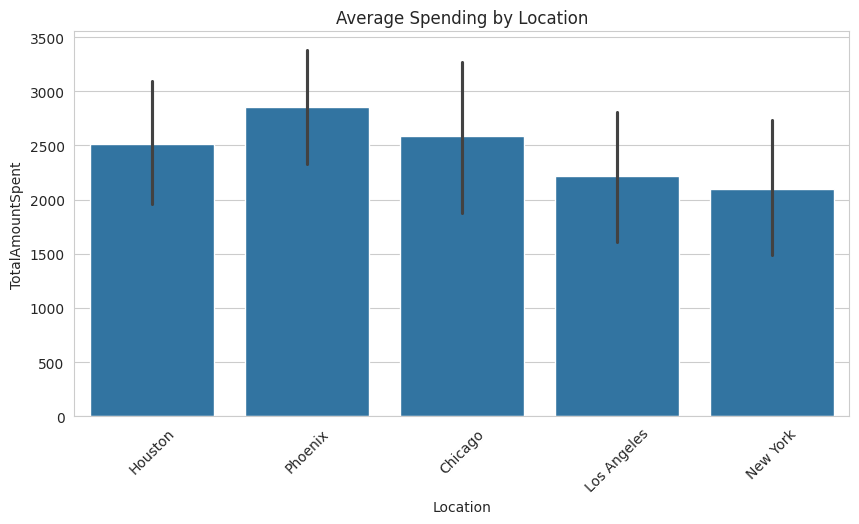

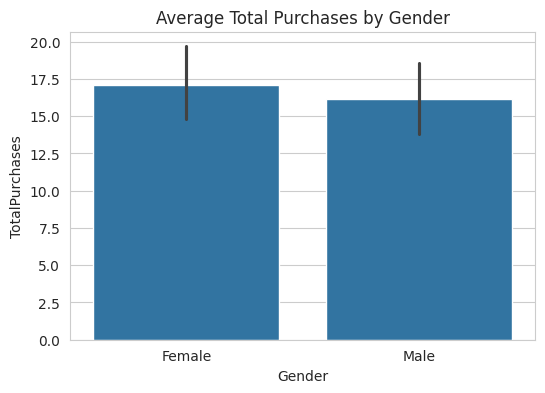

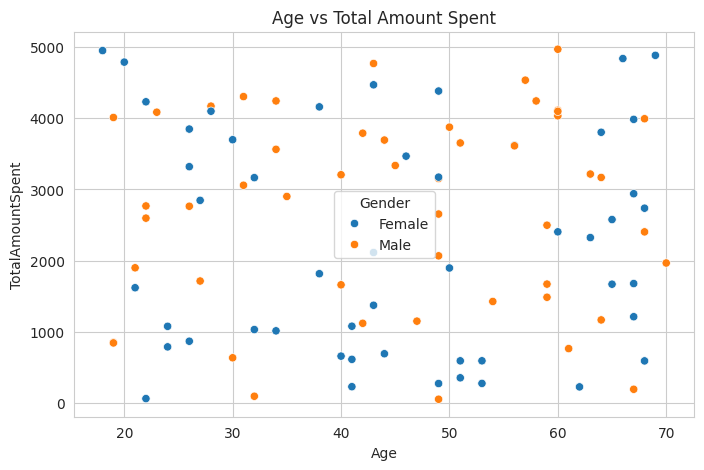

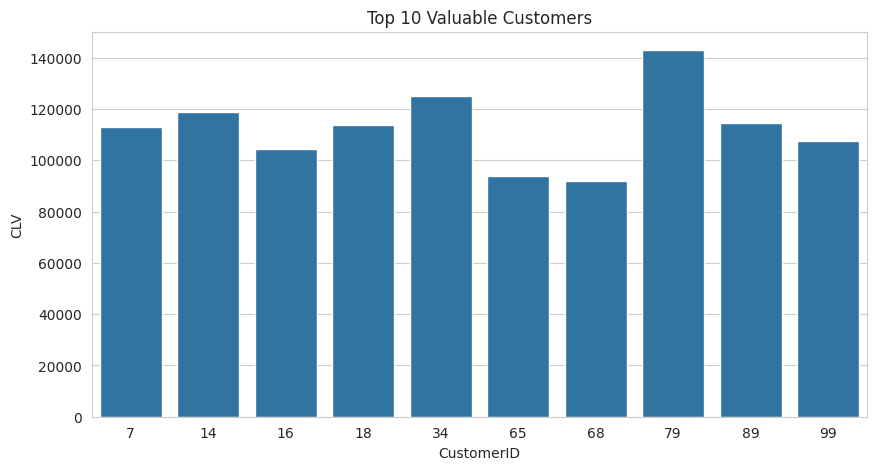

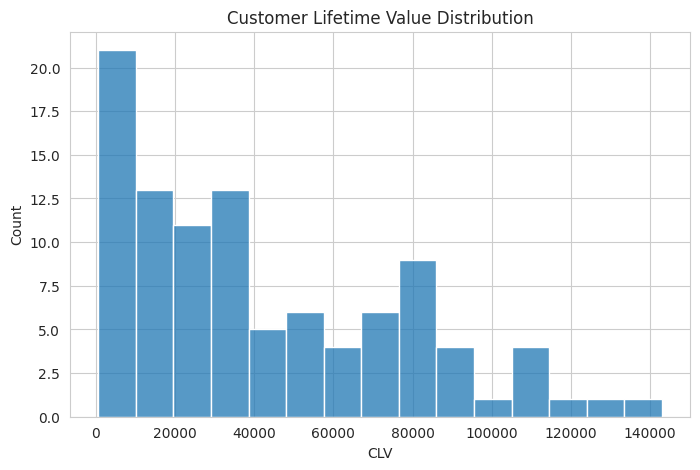

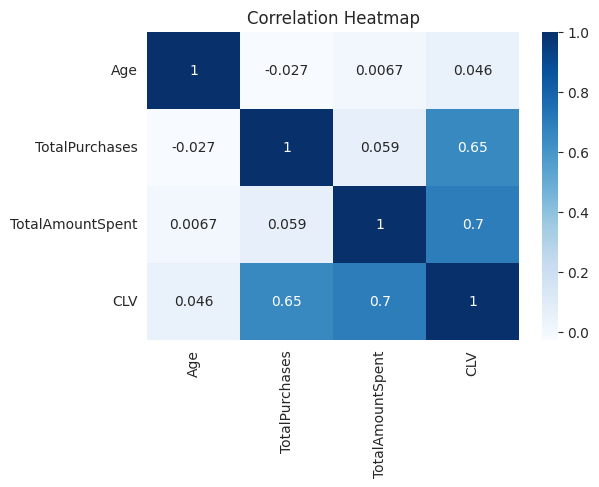



=
BUSINESS INSIGHTS
=
Insight 1
Female customers purchase more frequently but spend less per transaction than male customers.
Recommendation: Provide loyalty rewards and discount coupons to female customers.

Insight 2
Customers with the highest CLV are the most valuable.
Recommendation: Offer VIP membership and personalized offers.

Insight 3
Some locations generate higher sales than others.
Recommendation: Increase marketing and advertisements in high-performing locations.

Insight 4
Customers with low purchase frequency may stop buying.
Recommendation: Send reminder emails, coupons, and cashback offers.

Insight 5
Middle-aged customers contribute significantly to revenue.
Recommendation: Launch targeted campaigns for these age groups.

Insight 6
Frequent customers are more loyal.
Recommendation: Start a customer loyalty program.

Insight 7
High-spending customers should receive personalized recommendations.
Recommendation: Suggest premium products and exclusive deals.

=
PROJECT C

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("customer_data.csv")
print("CUSTOMER DATA")
print(df.head())
print("Dataset Shape")
print(df.shape)
print("Column Names")
print(df.columns)
print("Dataset Information")
print(df.info())
print("Missing Values")
print(df.isnull().sum())
print("Duplicate Rows")
print(df.duplicated().sum())

#  Data Cleaning
df.drop_duplicates(inplace=True)

df["Age"].fillna(df["Age"].mean(), inplace=True)
df["Gender"].fillna("Unknown", inplace=True)
df["Location"].fillna("Unknown", inplace=True)
df["TotalPurchases"].fillna(0, inplace=True)
df["TotalAmountSpent"].fillna(0, inplace=True)

print("Data Cleaning Completed")
print("Statistical Summary")
print(df.describe())
print("Gender Distribution")
print(df["Gender"].value_counts())

#  Location Distribution
print("Location Distribution")
print(df["Location"].value_counts())

# Average Spending by Gender
print("Average Amount Spent by Gender")
avg_gender = df.groupby("Gender")["TotalAmountSpent"].mean()
print(avg_gender)

#  Average Spending by Age
print("Average Amount Spent by Age")
avg_age = df.groupby("Age")["TotalAmountSpent"].mean()
print(avg_age)

# Total Spending by Location
print("Total Amount Spent by Location")
location_sales = df.groupby("Location")["TotalAmountSpent"].sum()
print(location_sales)

# Customer Lifetime Value (CLV)
df["CLV"] = df["TotalPurchases"]
print("Customer Lifetime Value")
print(df[["CustomerID","CLV"]].head())

# Top 10 Valuable Customers
top_customers = df.sort_values(by="CLV", ascending=False)
print("Top 10 Valuable Customers")
print(top_customers[["CustomerID","Age","Gender","Location","CLV"]].head(10))

# Loyal Customers
loyal = df[df["TotalPurchases"] >= 20]
print("Loyal Customers")
print(loyal[["CustomerID","TotalPurchases"]])


# Churn Customers
churn = df[df["TotalPurchases"] <= 5]
print("Potential Churn Customers")
print(churn[["CustomerID","TotalPurchases"]])

# Visualizations
sns.set_style("whitegrid")

# Gender Distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Gender")
plt.title("Gender Distribution")
plt.show()

# Age Distribution
plt.figure(figsize=(8,5))
sns.histplot(df["Age"], bins=10, kde=True)
plt.title("Age Distribution")
plt.show()

# Customers by Location
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="Location")
plt.title("Customers by Location")
plt.xticks(rotation=45)
plt.show()

# Average Spending by Gender
plt.figure(figsize=(6,4))
sns.barplot(data=df, x="Gender", y="TotalAmountSpent")
plt.title("Average Spending by Gender")
plt.show()

# Spending by Location
plt.figure(figsize=(10,5))
sns.barplot(data=df, x="Location", y="TotalAmountSpent")
plt.title("Average Spending by Location")
plt.xticks(rotation=45)
plt.show()

# Total Purchases by Gender

plt.figure(figsize=(6,4))
sns.barplot(data=df, x="Gender", y="TotalPurchases")
plt.title("Average Total Purchases by Gender")
plt.show()

# Age vs Spending
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,
                x="Age",
                y="TotalAmountSpent",
                hue="Gender")

plt.title("Age vs Total Amount Spent")
plt.show()

# Top 10 Customers
plt.figure(figsize=(10,5))
sns.barplot(data=top_customers.head(10),
            x="CustomerID",
            y="CLV")

plt.title("Top 10 Valuable Customers")
plt.show()

# CLV Distribution
plt.figure(figsize=(8,5))
sns.histplot(df["CLV"], bins=15)
plt.title("Customer Lifetime Value Distribution")
plt.show()

# Correlation heatmap
plt.figure(figsize=(6,4))
corr = df[["Age","TotalPurchases","TotalAmountSpent","CLV"]].corr()
sns.heatmap(corr,
            annot=True,
            cmap="Blues")
plt.title("Correlation Heatmap")
plt.show()

# Business Insights
print("\n")
print("=")
print("BUSINESS INSIGHTS")
print("=")

print("Insight 1")
print("Female customers purchase more frequently but spend less per transaction than male customers.")
print("Recommendation: Provide loyalty rewards and discount coupons to female customers.")

print()
print("Insight 2")
print("Customers with the highest CLV are the most valuable.")
print("Recommendation: Offer VIP membership and personalized offers.")

print()
print("Insight 3")
print("Some locations generate higher sales than others.")
print("Recommendation: Increase marketing and advertisements in high-performing locations.")

print()
print("Insight 4")
print("Customers with low purchase frequency may stop buying.")
print("Recommendation: Send reminder emails, coupons, and cashback offers.")

print()
print("Insight 5")
print("Middle-aged customers contribute significantly to revenue.")
print("Recommendation: Launch targeted campaigns for these age groups.")

print()
print("Insight 6")
print("Frequent customers are more loyal.")
print("Recommendation: Start a customer loyalty program.")

print()
print("Insight 7")
print("High-spending customers should receive personalized recommendations.")
print("Recommendation: Suggest premium products and exclusive deals.")

print()
print("=")
print("PROJECT COMPLETED SUCCESSFULLY")
print("=")
